In [1]:
# ============================================================
# DAV - AIR QUALITY
# COMPLETE FINAL MODEL EVALUATION
# ============================================================

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, KFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    median_absolute_error,
    explained_variance_score,
    max_error,
    mean_absolute_percentage_error
)

from catboost import CatBoostRegressor


# ============================================================
# 1. LOAD DATA
# ============================================================

file_path = "../../Feature_engineered_datasets/air_quality_feature_engineered.csv"

df = pd.read_csv(file_path)

target = "Pollution_Score"

X = df.drop(columns=["Pollution_Score", "Pollution_Level"])
y = df[target]


# ============================================================
# 2. IDENTIFY COLUMNS
# ============================================================

categorical_cols = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numeric_cols = X.select_dtypes(
    exclude=["object", "category"]
).columns.tolist()


# ============================================================
# 3. PREPROCESSING
# ============================================================

preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_cols
        ),
        (
            "num",
            "passthrough",
            numeric_cols
        )
    ]
)


# ============================================================
# 4. TRAIN / TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)


# ============================================================
# 5. TRANSFORM DATA
# ============================================================

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)


# ============================================================
# 6. METRIC FUNCTION
# ============================================================

def calculate_metrics(y_true, y_pred, n_features):

    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)

    r2 = r2_score(y_true, y_pred)

    median_ae = median_absolute_error(
        y_true,
        y_pred
    )

    explained_variance = explained_variance_score(
        y_true,
        y_pred
    )

    maximum_error = max_error(
        y_true,
        y_pred
    )

    # NRMSE based on target range
    target_range = np.max(y_true) - np.min(y_true)

    if target_range != 0:
        nrmse = (rmse / target_range) * 100
    else:
        nrmse = np.nan

    # Adjusted R2
    n = len(y_true)

    if n > n_features + 1:
        adjusted_r2 = (
            1
            - ((1 - r2) * (n - 1))
            / (n - n_features - 1)
        )
    else:
        adjusted_r2 = np.nan

    # MAPE
    # Air Quality target is positive, so MAPE is valid
    mape = (
        mean_absolute_percentage_error(
            y_true,
            y_pred
        ) * 100
    )

    return {
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2,
        "Median_AE": median_ae,
        "Explained_Variance": explained_variance,
        "Max_Error": maximum_error,
        "NRMSE_percent": nrmse,
        "Adjusted_R2": adjusted_r2,
        "MAPE_percent": mape
    }


# ============================================================
# 7. STORE RESULTS
# ============================================================

results = []


# ============================================================
# 8. LINEAR REGRESSION
# ============================================================

lr = LinearRegression()

lr.fit(
    X_train_processed,
    y_train
)

lr_pred = lr.predict(
    X_test_processed
)

lr_metrics = calculate_metrics(
    y_test,
    lr_pred,
    X_test_processed.shape[1]
)

lr_metrics["Dataset"] = "Air Quality"
lr_metrics["Model"] = "Linear Regression"

results.append(lr_metrics)


# ============================================================
# 9. DECISION TREE
# ============================================================

dt = DecisionTreeRegressor(
    random_state=42
)

dt.fit(
    X_train_processed,
    y_train
)

dt_pred = dt.predict(
    X_test_processed
)

dt_metrics = calculate_metrics(
    y_test,
    dt_pred,
    X_test_processed.shape[1]
)

dt_metrics["Dataset"] = "Air Quality"
dt_metrics["Model"] = "Decision Tree"

results.append(dt_metrics)


# ============================================================
# 10. RANDOM FOREST
# ============================================================

rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf.fit(
    X_train_processed,
    y_train
)

rf_pred = rf.predict(
    X_test_processed
)

rf_metrics = calculate_metrics(
    y_test,
    rf_pred,
    X_test_processed.shape[1]
)

rf_metrics["Dataset"] = "Air Quality"
rf_metrics["Model"] = "Random Forest"

results.append(rf_metrics)


# ============================================================
# 11. PROPOSED HYBRID
#     LR + CatBoost + Gradient Boosting
#     OOF STACKING
# ============================================================

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

oof_predictions = np.zeros(
    (len(X_train_processed), 3)
)

test_predictions = np.zeros(
    (len(X_test_processed), 3, 5)
)


for fold, (train_idx, val_idx) in enumerate(
    kf.split(X_train_processed)
):

    X_tr = X_train_processed[train_idx]
    X_val = X_train_processed[val_idx]

    y_tr = y_train.iloc[train_idx]

    # -----------------------------
    # Linear Regression
    # -----------------------------

    fold_lr = LinearRegression()

    fold_lr.fit(
        X_tr,
        y_tr
    )

    oof_predictions[val_idx, 0] = fold_lr.predict(
        X_val
    )

    test_predictions[:, 0, fold] = fold_lr.predict(
        X_test_processed
    )

    # -----------------------------
    # CatBoost
    # -----------------------------

    fold_cb = CatBoostRegressor(
        iterations=500,
        learning_rate=0.05,
        depth=6,
        loss_function="RMSE",
        random_seed=42,
        verbose=False
    )

    fold_cb.fit(
        X_tr,
        y_tr
    )

    oof_predictions[val_idx, 1] = fold_cb.predict(
        X_val
    )

    test_predictions[:, 1, fold] = fold_cb.predict(
        X_test_processed
    )

    # -----------------------------
    # Gradient Boosting
    # -----------------------------

    fold_gb = GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        min_samples_split=5,
        min_samples_leaf=3,
        random_state=42
    )

    fold_gb.fit(
        X_tr,
        y_tr
    )

    oof_predictions[val_idx, 2] = fold_gb.predict(
        X_val
    )

    test_predictions[:, 2, fold] = fold_gb.predict(
        X_test_processed
    )


# ============================================================
# 12. META LEARNER
# ============================================================

meta_model = LinearRegression()

meta_model.fit(
    oof_predictions,
    y_train
)


# Average predictions from the 5 folds
test_base_predictions = np.mean(
    test_predictions,
    axis=2
)


# Final hybrid prediction
hybrid_pred = meta_model.predict(
    test_base_predictions
)


# ============================================================
# 13. HYBRID METRICS
# ============================================================

hybrid_metrics = calculate_metrics(
    y_test,
    hybrid_pred,
    3
)

hybrid_metrics["Dataset"] = "Air Quality"
hybrid_metrics["Model"] = "Proposed Hybrid"

results.append(hybrid_metrics)


# ============================================================
# 14. FINAL TABLE
# ============================================================

air_quality_final = pd.DataFrame(
    results
)

air_quality_final = air_quality_final[
    [
        "Dataset",
        "Model",
        "MAE",
        "MSE",
        "RMSE",
        "R2",
        "Median_AE",
        "Explained_Variance",
        "Max_Error",
        "NRMSE_percent",
        "Adjusted_R2",
        "MAPE_percent"
    ]
]

air_quality_final = air_quality_final.round(4)


# ============================================================
# 15. DISPLAY
# ============================================================

print("\n======================================================")
print("FINAL AIR QUALITY METRICS")
print("======================================================\n")

display(air_quality_final)


# ============================================================
# 16. SAVE
# ============================================================

import os

os.makedirs(
    "../../Hybrid_Model/Results",
    exist_ok=True
)

air_quality_final.to_csv(
    "../../Hybrid_Model/Results/Air_Quality_Final_Metrics.csv",
    index=False
)

print(
    "\nSaved: Hybrid_Model/Results/Air_Quality_Final_Metrics.csv"
)


FINAL AIR QUALITY METRICS



,Dataset,Model,MAE,MSE,RMSE,R2,Median_AE,Explained_Variance,Max_Error,NRMSE_percent,Adjusted_R2,MAPE_percent
0,Air Quality,Linear Regression,0.0000,0.0000,0.0000,1.000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000
1,Air Quality,Decision Tree,0.1381,0.0373,0.1931,0.949,0.1007,0.9493,0.8227,7.4294,0.9353,18.7820
2,Air Quality,Random Forest,0.0845,0.0124,0.1114,0.983,0.0599,0.9831,0.3700,4.2888,0.9784,11.9445
3,Air Quality,Proposed Hybrid,0.0000,0.0000,0.0000,1.000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000



Saved: Hybrid_Model/Results/Air_Quality_Final_Metrics.csv


In [2]:
# ============================================================
# DAV - WEATHER
# COMPLETE FINAL MODEL EVALUATION
# Controlled version WITHOUT Apparent Temperature
# ============================================================

import pandas as pd
import numpy as np
import os

from sklearn.model_selection import train_test_split, KFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    median_absolute_error,
    explained_variance_score,
    max_error
)

from catboost import CatBoostRegressor


# ============================================================
# 1. LOAD DATA
# ============================================================

file_path = "../../Feature_engineered_datasets/weather_feature_engineered.csv"

df = pd.read_csv(file_path)

target = "Temperature (C)"

print("Original shape:", df.shape)


# ============================================================
# 2. REMOVE TARGET-RELATED / HIGH-CARDINALITY FEATURES
# ============================================================

columns_to_drop = [
    "Temperature (C)",
    "Temperature_Difference",
    "Apparent Temperature (C)",
    "Formatted Date",
    "Daily Summary"
]

X = df.drop(
    columns=columns_to_drop,
    errors="ignore"
)

y = df[target]


# ============================================================
# 3. IDENTIFY CATEGORICAL AND NUMERICAL FEATURES
# ============================================================

categorical_cols = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numeric_cols = X.select_dtypes(
    exclude=["object", "category"]
).columns.tolist()

print("\nCategorical columns:")
print(categorical_cols)

print("\nNumerical columns:")
print(numeric_cols)


# ============================================================
# 4. PREPROCESSING
# ============================================================

preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_cols
        ),
        (
            "num",
            "passthrough",
            numeric_cols
        )
    ]
)


# ============================================================
# 5. TRAIN / TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)


# ============================================================
# 6. TRANSFORM
# ============================================================

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("\nProcessed training shape:",
      X_train_processed.shape)

print("Processed testing shape:",
      X_test_processed.shape)


# ============================================================
# 7. METRIC FUNCTION
# ============================================================

def calculate_metrics(
    y_true,
    y_pred,
    n_features,
    mape_allowed=False
):

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    mse = mean_squared_error(
        y_true,
        y_pred
    )

    rmse = np.sqrt(mse)

    r2 = r2_score(
        y_true,
        y_pred
    )

    median_ae = median_absolute_error(
        y_true,
        y_pred
    )

    explained_variance = explained_variance_score(
        y_true,
        y_pred
    )

    maximum_error = max_error(
        y_true,
        y_pred
    )

    # --------------------------------------------------------
    # NRMSE
    # Normalized using target range
    # --------------------------------------------------------

    target_range = (
        np.max(y_true)
        - np.min(y_true)
    )

    if target_range != 0:

        nrmse = (
            rmse / target_range
        ) * 100

    else:

        nrmse = np.nan


    # --------------------------------------------------------
    # Adjusted R²
    # --------------------------------------------------------

    n = len(y_true)

    if n > n_features + 1:

        adjusted_r2 = (
            1
            -
            (
                (1 - r2)
                * (n - 1)
                /
                (n - n_features - 1)
            )
        )

    else:

        adjusted_r2 = np.nan


    # --------------------------------------------------------
    # MAPE
    #
    # Weather has zero/near-zero actual temperatures,
    # therefore MAPE is NOT considered valid.
    # --------------------------------------------------------

    if mape_allowed:

        non_zero_mask = (
            np.abs(y_true) > 1e-8
        )

        if non_zero_mask.sum() > 0:

            mape = np.mean(
                np.abs(
                    (
                        y_true[non_zero_mask]
                        -
                        y_pred[non_zero_mask]
                    )
                    /
                    y_true[non_zero_mask]
                )
            ) * 100

        else:

            mape = np.nan

    else:

        mape = np.nan


    return {
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2,
        "Median_AE": median_ae,
        "Explained_Variance": explained_variance,
        "Max_Error": maximum_error,
        "NRMSE_percent": nrmse,
        "Adjusted_R2": adjusted_r2,
        "MAPE_percent": mape
    }


# ============================================================
# 8. RESULTS STORAGE
# ============================================================

results = []


# ============================================================
# 9. LINEAR REGRESSION
# ============================================================

lr = LinearRegression()

lr.fit(
    X_train_processed,
    y_train
)

lr_pred = lr.predict(
    X_test_processed
)

lr_metrics = calculate_metrics(
    y_test,
    lr_pred,
    X_test_processed.shape[1],
    mape_allowed=False
)

lr_metrics["Dataset"] = "Weather"
lr_metrics["Model"] = "Linear Regression"

results.append(lr_metrics)


# ============================================================
# 10. DECISION TREE
# ============================================================

dt = DecisionTreeRegressor(
    random_state=42
)

dt.fit(
    X_train_processed,
    y_train
)

dt_pred = dt.predict(
    X_test_processed
)

dt_metrics = calculate_metrics(
    y_test,
    dt_pred,
    X_test_processed.shape[1],
    mape_allowed=False
)

dt_metrics["Dataset"] = "Weather"
dt_metrics["Model"] = "Decision Tree"

results.append(dt_metrics)


# ============================================================
# 11. RANDOM FOREST
# ============================================================

rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf.fit(
    X_train_processed,
    y_train
)

rf_pred = rf.predict(
    X_test_processed
)

rf_metrics = calculate_metrics(
    y_test,
    rf_pred,
    X_test_processed.shape[1],
    mape_allowed=False
)

rf_metrics["Dataset"] = "Weather"
rf_metrics["Model"] = "Random Forest"

results.append(rf_metrics)


# ============================================================
# 12. PROPOSED HYBRID
#
# LR + CatBoost + Gradient Boosting
# OOF STACKING
# ============================================================

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

oof_predictions = np.zeros(
    (len(X_train_processed), 3)
)

test_predictions = np.zeros(
    (len(X_test_processed), 3, 5)
)


for fold, (train_idx, val_idx) in enumerate(
    kf.split(X_train_processed)
):

    X_tr = X_train_processed[train_idx]
    X_val = X_train_processed[val_idx]

    y_tr = y_train.iloc[train_idx]


    # --------------------------------------------------------
    # Linear Regression
    # --------------------------------------------------------

    fold_lr = LinearRegression()

    fold_lr.fit(
        X_tr,
        y_tr
    )

    oof_predictions[val_idx, 0] = (
        fold_lr.predict(X_val)
    )

    test_predictions[:, 0, fold] = (
        fold_lr.predict(X_test_processed)
    )


    # --------------------------------------------------------
    # CatBoost
    # --------------------------------------------------------

    fold_cb = CatBoostRegressor(
        iterations=500,
        learning_rate=0.05,
        depth=6,
        loss_function="RMSE",
        random_seed=42,
        verbose=False
    )

    fold_cb.fit(
        X_tr,
        y_tr
    )

    oof_predictions[val_idx, 1] = (
        fold_cb.predict(X_val)
    )

    test_predictions[:, 1, fold] = (
        fold_cb.predict(X_test_processed)
    )


    # --------------------------------------------------------
    # Gradient Boosting
    # --------------------------------------------------------

    fold_gb = GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        min_samples_split=5,
        min_samples_leaf=3,
        random_state=42
    )

    fold_gb.fit(
        X_tr,
        y_tr
    )

    oof_predictions[val_idx, 2] = (
        fold_gb.predict(X_val)
    )

    test_predictions[:, 2, fold] = (
        fold_gb.predict(X_test_processed)
    )


# ============================================================
# 13. LINEAR META-LEARNER
# ============================================================

meta_model = LinearRegression()

meta_model.fit(
    oof_predictions,
    y_train
)


# ============================================================
# 14. TEST BASE MODEL PREDICTIONS
# ============================================================

test_base_predictions = np.mean(
    test_predictions,
    axis=2
)


# ============================================================
# 15. FINAL HYBRID PREDICTION
# ============================================================

hybrid_pred = meta_model.predict(
    test_base_predictions
)


# ============================================================
# 16. HYBRID METRICS
# ============================================================

hybrid_metrics = calculate_metrics(
    y_test,
    hybrid_pred,
    3,
    mape_allowed=False
)

hybrid_metrics["Dataset"] = "Weather"
hybrid_metrics["Model"] = "Proposed Hybrid"

results.append(hybrid_metrics)


# ============================================================
# 17. FINAL WEATHER TABLE
# ============================================================

weather_final = pd.DataFrame(
    results
)

weather_final = weather_final[
    [
        "Dataset",
        "Model",
        "MAE",
        "MSE",
        "RMSE",
        "R2",
        "Median_AE",
        "Explained_Variance",
        "Max_Error",
        "NRMSE_percent",
        "Adjusted_R2",
        "MAPE_percent"
    ]
]

weather_final = weather_final.round(4)


# ============================================================
# 18. DISPLAY
# ============================================================

print("\n======================================================")
print("FINAL WEATHER METRICS")
print("======================================================\n")

display(weather_final)


# ============================================================
# 19. SAVE
# ============================================================

os.makedirs(
    "../../Hybrid_Model/Results",
    exist_ok=True
)

weather_final.to_csv(
    "../../Hybrid_Model/Results/Weather_Final_Metrics.csv",
    index=False
)

print(
    "\nSaved:"
)

print(
    "Hybrid_Model/Results/Weather_Final_Metrics.csv"
)

Original shape: (96429, 18)

Categorical columns:
['Summary', 'Precip Type', 'DayOfWeek', 'Season', 'Wind_Chill_Indicator']

Numerical columns:
['Humidity', 'Wind Speed (km/h)', 'Wind Bearing (degrees)', 'Visibility (km)', 'Pressure (millibars)', 'Year', 'Month', 'Hour']

Processed training shape: (77143, 50)
Processed testing shape: (19286, 50)

FINAL WEATHER METRICS



,Dataset,Model,MAE,MSE,RMSE,R2,Median_AE,Explained_Variance,Max_Error,NRMSE_percent,Adjusted_R2,MAPE_percent
0,Weather,Linear Regression,3.2656,17.2090,4.1484,0.8123,2.7206,0.8123,33.4449,7.0444,0.8118,NaN
1,Weather,Decision Tree,1.8121,7.5590,2.7494,0.9176,1.0889,0.9176,21.2333,4.6687,0.9173,NaN
2,Weather,Random Forest,1.4283,3.7843,1.9453,0.9587,1.0610,0.9587,14.2012,3.3034,0.9586,NaN
3,Weather,Proposed Hybrid,1.9146,5.8729,2.4234,0.9360,1.6164,0.9360,17.6718,4.1152,0.9359,NaN



Saved:
Hybrid_Model/Results/Weather_Final_Metrics.csv


In [3]:
# ============================================================
# DAV - ENERGY
# COMPLETE FINAL MODEL EVALUATION
# ============================================================

import pandas as pd
import numpy as np
import os

from sklearn.model_selection import train_test_split, KFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    median_absolute_error,
    explained_variance_score,
    max_error
)

from catboost import CatBoostRegressor


# ============================================================
# 1. LOAD DATA
# ============================================================

file_path = "../../Feature_engineered_datasets/energy_feature_engineered.csv"

df = pd.read_csv(file_path)

target = "EnergyConsumption"

print("Original shape:", df.shape)


# ============================================================
# 2. REMOVE TARGET-RELATED / LEAKAGE-PRONE FEATURES
# ============================================================

columns_to_drop = [
    "EnergyConsumption",
    "Energy_Per_Occupant",
    "Renewable_Energy_Ratio",
    "Energy_Per_SquareFoot"
]

X = df.drop(
    columns=columns_to_drop,
    errors="ignore"
)

y = df[target]


# ============================================================
# 3. IDENTIFY CATEGORICAL AND NUMERICAL FEATURES
# ============================================================

categorical_cols = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numeric_cols = X.select_dtypes(
    exclude=["object", "category"]
).columns.tolist()

print("\nCategorical columns:")
print(categorical_cols)

print("\nNumerical columns:")
print(numeric_cols)


# ============================================================
# 4. PREPROCESSING
# ============================================================

preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_cols
        ),
        (
            "num",
            "passthrough",
            numeric_cols
        )
    ]
)


# ============================================================
# 5. TRAIN / TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)


# ============================================================
# 6. TRANSFORM DATA
# ============================================================

X_train_processed = preprocessor.fit_transform(
    X_train
)

X_test_processed = preprocessor.transform(
    X_test
)

print(
    "\nProcessed training shape:",
    X_train_processed.shape
)

print(
    "Processed testing shape:",
    X_test_processed.shape
)


# ============================================================
# 7. METRIC FUNCTION
# ============================================================

def calculate_metrics(
    y_true,
    y_pred,
    n_features
):

    # --------------------------------------------------------
    # MAE
    # --------------------------------------------------------

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    # --------------------------------------------------------
    # MSE
    # --------------------------------------------------------

    mse = mean_squared_error(
        y_true,
        y_pred
    )

    # --------------------------------------------------------
    # RMSE
    # --------------------------------------------------------

    rmse = np.sqrt(mse)

    # --------------------------------------------------------
    # R2
    # --------------------------------------------------------

    r2 = r2_score(
        y_true,
        y_pred
    )

    # --------------------------------------------------------
    # Median Absolute Error
    # --------------------------------------------------------

    median_ae = median_absolute_error(
        y_true,
        y_pred
    )

    # --------------------------------------------------------
    # Explained Variance
    # --------------------------------------------------------

    explained_variance = explained_variance_score(
        y_true,
        y_pred
    )

    # --------------------------------------------------------
    # Maximum Error
    # --------------------------------------------------------

    maximum_error = max_error(
        y_true,
        y_pred
    )

    # --------------------------------------------------------
    # NRMSE
    # Normalized by target range
    # --------------------------------------------------------

    target_range = (
        np.max(y_true)
        -
        np.min(y_true)
    )

    if target_range != 0:

        nrmse = (
            rmse
            /
            target_range
        ) * 100

    else:

        nrmse = np.nan


    # --------------------------------------------------------
    # Adjusted R2
    # --------------------------------------------------------

    n = len(y_true)

    if n > n_features + 1:

        adjusted_r2 = (
            1
            -
            (
                (1 - r2)
                *
                (n - 1)
                /
                (n - n_features - 1)
            )
        )

    else:

        adjusted_r2 = np.nan


    # --------------------------------------------------------
    # MAPE
    #
    # EnergyConsumption is positive, so MAPE is valid.
    # --------------------------------------------------------

    non_zero_mask = (
        np.abs(y_true) > 1e-8
    )

    if non_zero_mask.sum() > 0:

        mape = np.mean(
            np.abs(
                (
                    y_true[non_zero_mask]
                    -
                    y_pred[non_zero_mask]
                )
                /
                y_true[non_zero_mask]
            )
        ) * 100

    else:

        mape = np.nan


    return {
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2,
        "Median_AE": median_ae,
        "Explained_Variance": explained_variance,
        "Max_Error": maximum_error,
        "NRMSE_percent": nrmse,
        "Adjusted_R2": adjusted_r2,
        "MAPE_percent": mape
    }


# ============================================================
# 8. RESULTS STORAGE
# ============================================================

results = []


# ============================================================
# 9. LINEAR REGRESSION
# ============================================================

lr = LinearRegression()

lr.fit(
    X_train_processed,
    y_train
)

lr_pred = lr.predict(
    X_test_processed
)

lr_metrics = calculate_metrics(
    y_test,
    lr_pred,
    X_test_processed.shape[1]
)

lr_metrics["Dataset"] = "Energy"
lr_metrics["Model"] = "Linear Regression"

results.append(lr_metrics)


# ============================================================
# 10. DECISION TREE
# ============================================================

dt = DecisionTreeRegressor(
    random_state=42
)

dt.fit(
    X_train_processed,
    y_train
)

dt_pred = dt.predict(
    X_test_processed
)

dt_metrics = calculate_metrics(
    y_test,
    dt_pred,
    X_test_processed.shape[1]
)

dt_metrics["Dataset"] = "Energy"
dt_metrics["Model"] = "Decision Tree"

results.append(dt_metrics)


# ============================================================
# 11. RANDOM FOREST
# ============================================================

rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf.fit(
    X_train_processed,
    y_train
)

rf_pred = rf.predict(
    X_test_processed
)

rf_metrics = calculate_metrics(
    y_test,
    rf_pred,
    X_test_processed.shape[1]
)

rf_metrics["Dataset"] = "Energy"
rf_metrics["Model"] = "Random Forest"

results.append(rf_metrics)


# ============================================================
# 12. PROPOSED HYBRID
#
# LR + CatBoost + Gradient Boosting
# OOF STACKING
# ============================================================

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

oof_predictions = np.zeros(
    (len(X_train_processed), 3)
)

test_predictions = np.zeros(
    (len(X_test_processed), 3, 5)
)


for fold, (train_idx, val_idx) in enumerate(
    kf.split(X_train_processed)
):

    X_tr = X_train_processed[train_idx]
    X_val = X_train_processed[val_idx]

    y_tr = y_train.iloc[train_idx]


    # --------------------------------------------------------
    # Linear Regression
    # --------------------------------------------------------

    fold_lr = LinearRegression()

    fold_lr.fit(
        X_tr,
        y_tr
    )

    oof_predictions[val_idx, 0] = (
        fold_lr.predict(X_val)
    )

    test_predictions[:, 0, fold] = (
        fold_lr.predict(X_test_processed)
    )


    # --------------------------------------------------------
    # CatBoost
    # --------------------------------------------------------

    fold_cb = CatBoostRegressor(
        iterations=500,
        learning_rate=0.05,
        depth=6,
        loss_function="RMSE",
        random_seed=42,
        verbose=False
    )

    fold_cb.fit(
        X_tr,
        y_tr
    )

    oof_predictions[val_idx, 1] = (
        fold_cb.predict(X_val)
    )

    test_predictions[:, 1, fold] = (
        fold_cb.predict(X_test_processed)
    )


    # --------------------------------------------------------
    # Gradient Boosting
    # --------------------------------------------------------

    fold_gb = GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        min_samples_split=5,
        min_samples_leaf=3,
        random_state=42
    )

    fold_gb.fit(
        X_tr,
        y_tr
    )

    oof_predictions[val_idx, 2] = (
        fold_gb.predict(X_val)
    )

    test_predictions[:, 2, fold] = (
        fold_gb.predict(X_test_processed)
    )


# ============================================================
# 13. LINEAR META-LEARNER
# ============================================================

meta_model = LinearRegression()

meta_model.fit(
    oof_predictions,
    y_train
)


# ============================================================
# 14. TEST BASE MODEL PREDICTIONS
# ============================================================

test_base_predictions = np.mean(
    test_predictions,
    axis=2
)


# ============================================================
# 15. FINAL HYBRID PREDICTION
# ============================================================

hybrid_pred = meta_model.predict(
    test_base_predictions
)


# ============================================================
# 16. HYBRID METRICS
# ============================================================

hybrid_metrics = calculate_metrics(
    y_test,
    hybrid_pred,
    3
)

hybrid_metrics["Dataset"] = "Energy"
hybrid_metrics["Model"] = "Proposed Hybrid"

results.append(hybrid_metrics)


# ============================================================
# 17. FINAL ENERGY TABLE
# ============================================================

energy_final = pd.DataFrame(
    results
)

energy_final = energy_final[
    [
        "Dataset",
        "Model",
        "MAE",
        "MSE",
        "RMSE",
        "R2",
        "Median_AE",
        "Explained_Variance",
        "Max_Error",
        "NRMSE_percent",
        "Adjusted_R2",
        "MAPE_percent"
    ]
]

energy_final = energy_final.round(4)


# ============================================================
# 18. DISPLAY
# ============================================================

print("\n======================================================")
print("FINAL ENERGY METRICS")
print("======================================================\n")

display(energy_final)


# ============================================================
# 19. SAVE
# ============================================================

os.makedirs(
    "../../Hybrid_Model/Results",
    exist_ok=True
)

energy_final.to_csv(
    "../../Hybrid_Model/Results/Energy_Final_Metrics.csv",
    index=False
)

print(
    "\nSaved:"
)

print(
    "Hybrid_Model/Results/Energy_Final_Metrics.csv"
)

Original shape: (1000, 19)

Categorical columns:
['Timestamp', 'HVACUsage', 'LightingUsage', 'DayOfWeek', 'Holiday', 'Weekend']

Numerical columns:
['Temperature', 'Humidity', 'SquareFootage', 'Occupancy', 'RenewableEnergy', 'Hour', 'Month', 'HVAC_Status', 'Lighting_Status']

Processed training shape: (800, 824)
Processed testing shape: (200, 824)

FINAL ENERGY METRICS



,Dataset,Model,MAE,MSE,RMSE,R2,Median_AE,Explained_Variance,Max_Error,NRMSE_percent,Adjusted_R2,MAPE_percent
0,Energy,Linear Regression,4.0910,26.6669,5.1640,0.5929,3.4197,0.5930,17.9852,12.6990,NaN,5.4222
1,Energy,Decision Tree,5.5513,48.6729,6.9766,0.2569,4.3107,0.2572,21.4642,17.1564,NaN,7.3262
2,Energy,Random Forest,4.3428,29.3336,5.4161,0.5522,3.8628,0.5522,18.8513,13.3188,NaN,5.7497
3,Energy,Proposed Hybrid,4.1285,27.0009,5.1962,0.5878,3.6038,0.5878,17.9037,12.7782,0.5815,5.4722



Saved:
Hybrid_Model/Results/Energy_Final_Metrics.csv


In [6]:
import pandas as pd
import os

# ---------------------------------------------------------
# 1. Load final metric files
# ---------------------------------------------------------

air = pd.read_csv("../../Hybrid_Model/Results/Air_Quality_Final_Metrics.csv")
weather = pd.read_csv("../../Hybrid_Model/Results/Weather_Final_Metrics.csv")
energy = pd.read_csv("../../Hybrid_Model/Results/Energy_Final_Metrics.csv")

# ---------------------------------------------------------
# 2. Set dataset names
# ---------------------------------------------------------

air["Dataset"] = "Air Quality"
weather["Dataset"] = "Weather"
energy["Dataset"] = "Energy"

# ---------------------------------------------------------
# 3. Combine all datasets
# ---------------------------------------------------------

final_metrics = pd.concat(
    [air, weather, energy],
    ignore_index=True
)

# ---------------------------------------------------------
# 4. Put Dataset column first
# ---------------------------------------------------------

cols = ["Dataset"] + [
    col for col in final_metrics.columns
    if col != "Dataset"
]

final_metrics = final_metrics[cols]

# ---------------------------------------------------------
# 5. Set required order
# ---------------------------------------------------------

dataset_order = [
    "Air Quality",
    "Weather",
    "Energy"
]

model_order = [
    "Linear Regression",
    "Decision Tree",
    "Random Forest",
    "Proposed Hybrid"
]

final_metrics["Dataset"] = pd.Categorical(
    final_metrics["Dataset"],
    categories=dataset_order,
    ordered=True
)

final_metrics["Model"] = pd.Categorical(
    final_metrics["Model"],
    categories=model_order,
    ordered=True
)

# Sort
final_metrics = final_metrics.sort_values(
    ["Dataset", "Model"]
).reset_index(drop=True)

# ---------------------------------------------------------
# 6. Round numerical values
# ---------------------------------------------------------

numeric_columns = final_metrics.select_dtypes(
    include="number"
).columns

final_metrics[numeric_columns] = final_metrics[numeric_columns].round(4)

# ---------------------------------------------------------
# 7. Display
# ---------------------------------------------------------

print("=" * 110)
print("FINAL DAV PROJECT — MASTER METRICS TABLE")
print("=" * 110)

display(final_metrics)

# ---------------------------------------------------------
# 8. Save CSV and Excel
# ---------------------------------------------------------

os.makedirs("../../Hybrid_Model/Results", exist_ok=True)

csv_path = "../../Hybrid_Model/Results/Final_DAV_Metrics_Table.csv"
excel_path = "../../Hybrid_Model/Results/Final_DAV_Metrics_Table.xlsx"

final_metrics.to_csv(csv_path, index=False)
final_metrics.to_excel(excel_path, index=False)

print("\n✅ CSV saved:")
print(csv_path)

print("\n✅ Excel saved:")
print(excel_path)

print("\nFinal table shape:", final_metrics.shape)

FINAL DAV PROJECT — MASTER METRICS TABLE


,Dataset,Model,MAE,MSE,RMSE,R2,Median_AE,Explained_Variance,Max_Error,NRMSE_percent,Adjusted_R2,MAPE_percent
0,Air Quality,Linear Regression,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000
1,Air Quality,Decision Tree,0.1381,0.0373,0.1931,0.9490,0.1007,0.9493,0.8227,7.4294,0.9353,18.7820
2,Air Quality,Random Forest,0.0845,0.0124,0.1114,0.9830,0.0599,0.9831,0.3700,4.2888,0.9784,11.9445
3,Air Quality,Proposed Hybrid,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000
4,Weather,Linear Regression,3.2656,17.2090,4.1484,0.8123,2.7206,0.8123,33.4449,7.0444,0.8118,NaN
5,Weather,Decision Tree,1.8121,7.5590,2.7494,0.9176,1.0889,0.9176,21.2333,4.6687,0.9173,NaN
6,Weather,Random Forest,1.4283,3.7843,1.9453,0.9587,1.0610,0.9587,14.2012,3.3034,0.9586,NaN
7,Weather,Proposed Hybrid,1.9146,5.8729,2.4234,0.9360,1.6164,0.9360,17.6718,4.1152,0.9359,NaN
8,Energy,Linear Regression,4.0910,26.6669,5.1640,0.5929,3.4197,0.5930,17.9852,12.6990,NaN,5.4222
9,Energy,Decision Tree,5.5513,48.6729,6.9766,0.2569,4.3107,0.2572,21.4642,17.1564,NaN,7.3262



✅ CSV saved:
../../Hybrid_Model/Results/Final_DAV_Metrics_Table.csv

✅ Excel saved:
../../Hybrid_Model/Results/Final_DAV_Metrics_Table.xlsx

Final table shape: (12, 12)


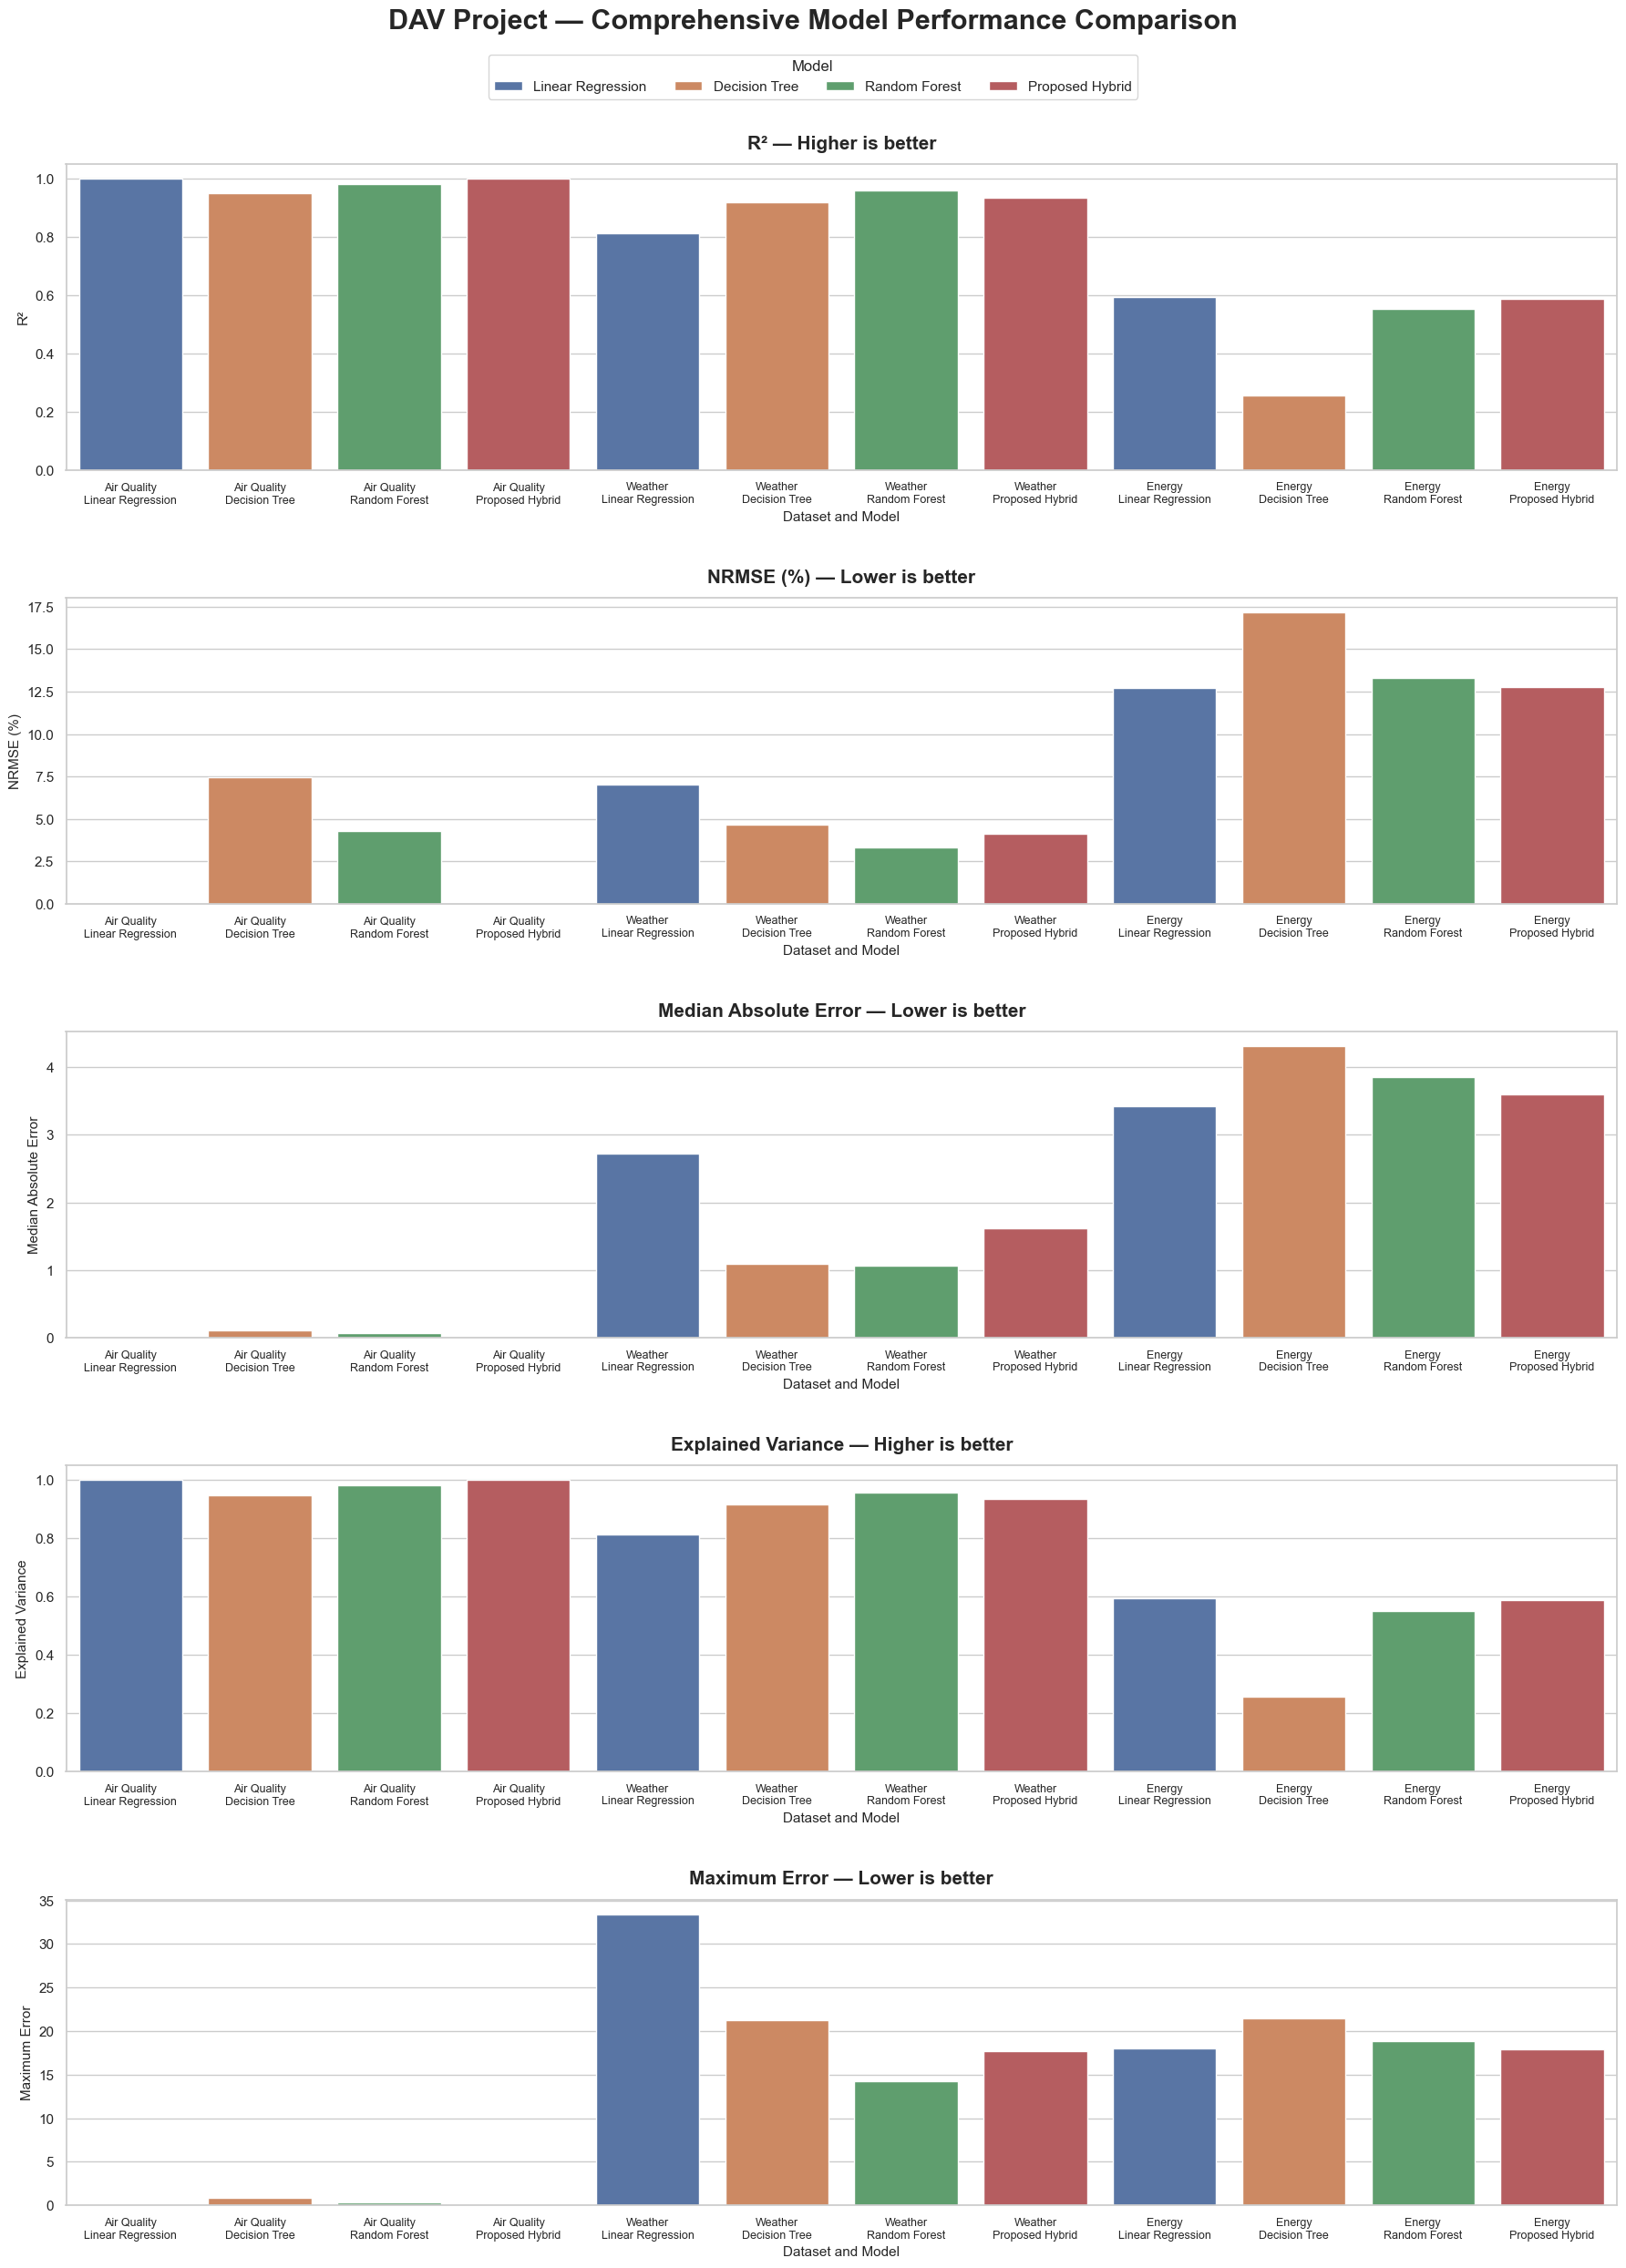


✅ FINAL COMBINED GRAPH SAVED:
../../Hybrid_Model/Results/DAV_Final_Combined_Performance_Comparison.png


In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# =========================================================
# 1. Load final master metrics table
# =========================================================

df = pd.read_csv(
    "../../Hybrid_Model/Results/Final_DAV_Metrics_Table.csv"
)

# Make sure ordering is correct
dataset_order = [
    "Air Quality",
    "Weather",
    "Energy"
]

model_order = [
    "Linear Regression",
    "Decision Tree",
    "Random Forest",
    "Proposed Hybrid"
]

df["Dataset"] = pd.Categorical(
    df["Dataset"],
    categories=dataset_order,
    ordered=True
)

df["Model"] = pd.Categorical(
    df["Model"],
    categories=model_order,
    ordered=True
)

df = df.sort_values(
    ["Dataset", "Model"]
).reset_index(drop=True)


# =========================================================
# 2. Create readable labels
# =========================================================

df["Label"] = (
    df["Dataset"].astype(str)
    + "\n"
    + df["Model"].astype(str)
)


# =========================================================
# 3. Metrics for the final comparison figure
# =========================================================

metrics = [
    ("R2", "R²", "Higher is better"),
    ("NRMSE_percent", "NRMSE (%)", "Lower is better"),
    ("Median_AE", "Median Absolute Error", "Lower is better"),
    ("Explained_Variance", "Explained Variance", "Higher is better"),
    ("Max_Error", "Maximum Error", "Lower is better")
]


# =========================================================
# 4. Create ONE figure with 5 panels
# =========================================================

sns.set_theme(
    style="whitegrid",
    context="notebook"
)

fig, axes = plt.subplots(
    5,
    1,
    figsize=(18, 25)
)

fig.suptitle(
    "DAV Project — Comprehensive Model Performance Comparison",
    fontsize=22,
    fontweight="bold",
    y=0.995
)


# =========================================================
# 5. Plot each metric
# =========================================================

for ax, (metric, title, direction) in zip(axes, metrics):

    sns.barplot(
        data=df,
        x="Label",
        y=metric,
        hue="Model",
        ax=ax,
        errorbar=None
    )

    ax.set_title(
        f"{title} — {direction}",
        fontsize=15,
        fontweight="bold",
        pad=12
    )

    ax.set_xlabel(
        "Dataset and Model",
        fontsize=11
    )

    ax.set_ylabel(
        title,
        fontsize=11
    )

    ax.tick_params(
        axis="x",
        rotation=0,
        labelsize=9
    )

    # Remove duplicate legend from individual plots
    if ax.get_legend() is not None:
        ax.get_legend().remove()


# =========================================================
# 6. Create ONE common legend
# =========================================================

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    title="Model",
    loc="upper center",
    bbox_to_anchor=(0.5, 0.978),
    ncol=4,
    frameon=True
)


# =========================================================
# 7. Improve spacing
# =========================================================

plt.tight_layout(
    rect=[0, 0, 1, 0.965],
    h_pad=3
)


# =========================================================
# 8. Save the single combined figure
# =========================================================

os.makedirs(
    "../../Hybrid_Model/Results",
    exist_ok=True
)

output_path = (
    "../../Hybrid_Model/Results/"
    "DAV_Final_Combined_Performance_Comparison.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\n✅ FINAL COMBINED GRAPH SAVED:")
print(output_path)

Using metrics file:
..\..\Hybrid_Model\Results\Final_DAV_Metrics_Table.csv

Loaded data:
(12, 12)
['Dataset', 'Model', 'MAE', 'MSE', 'RMSE', 'R2', 'Median_AE', 'Explained_Variance', 'Max_Error', 'NRMSE_percent', 'Adjusted_R2', 'MAPE_percent']

Verified:
3 datasets × 4 models
Total rows = 12


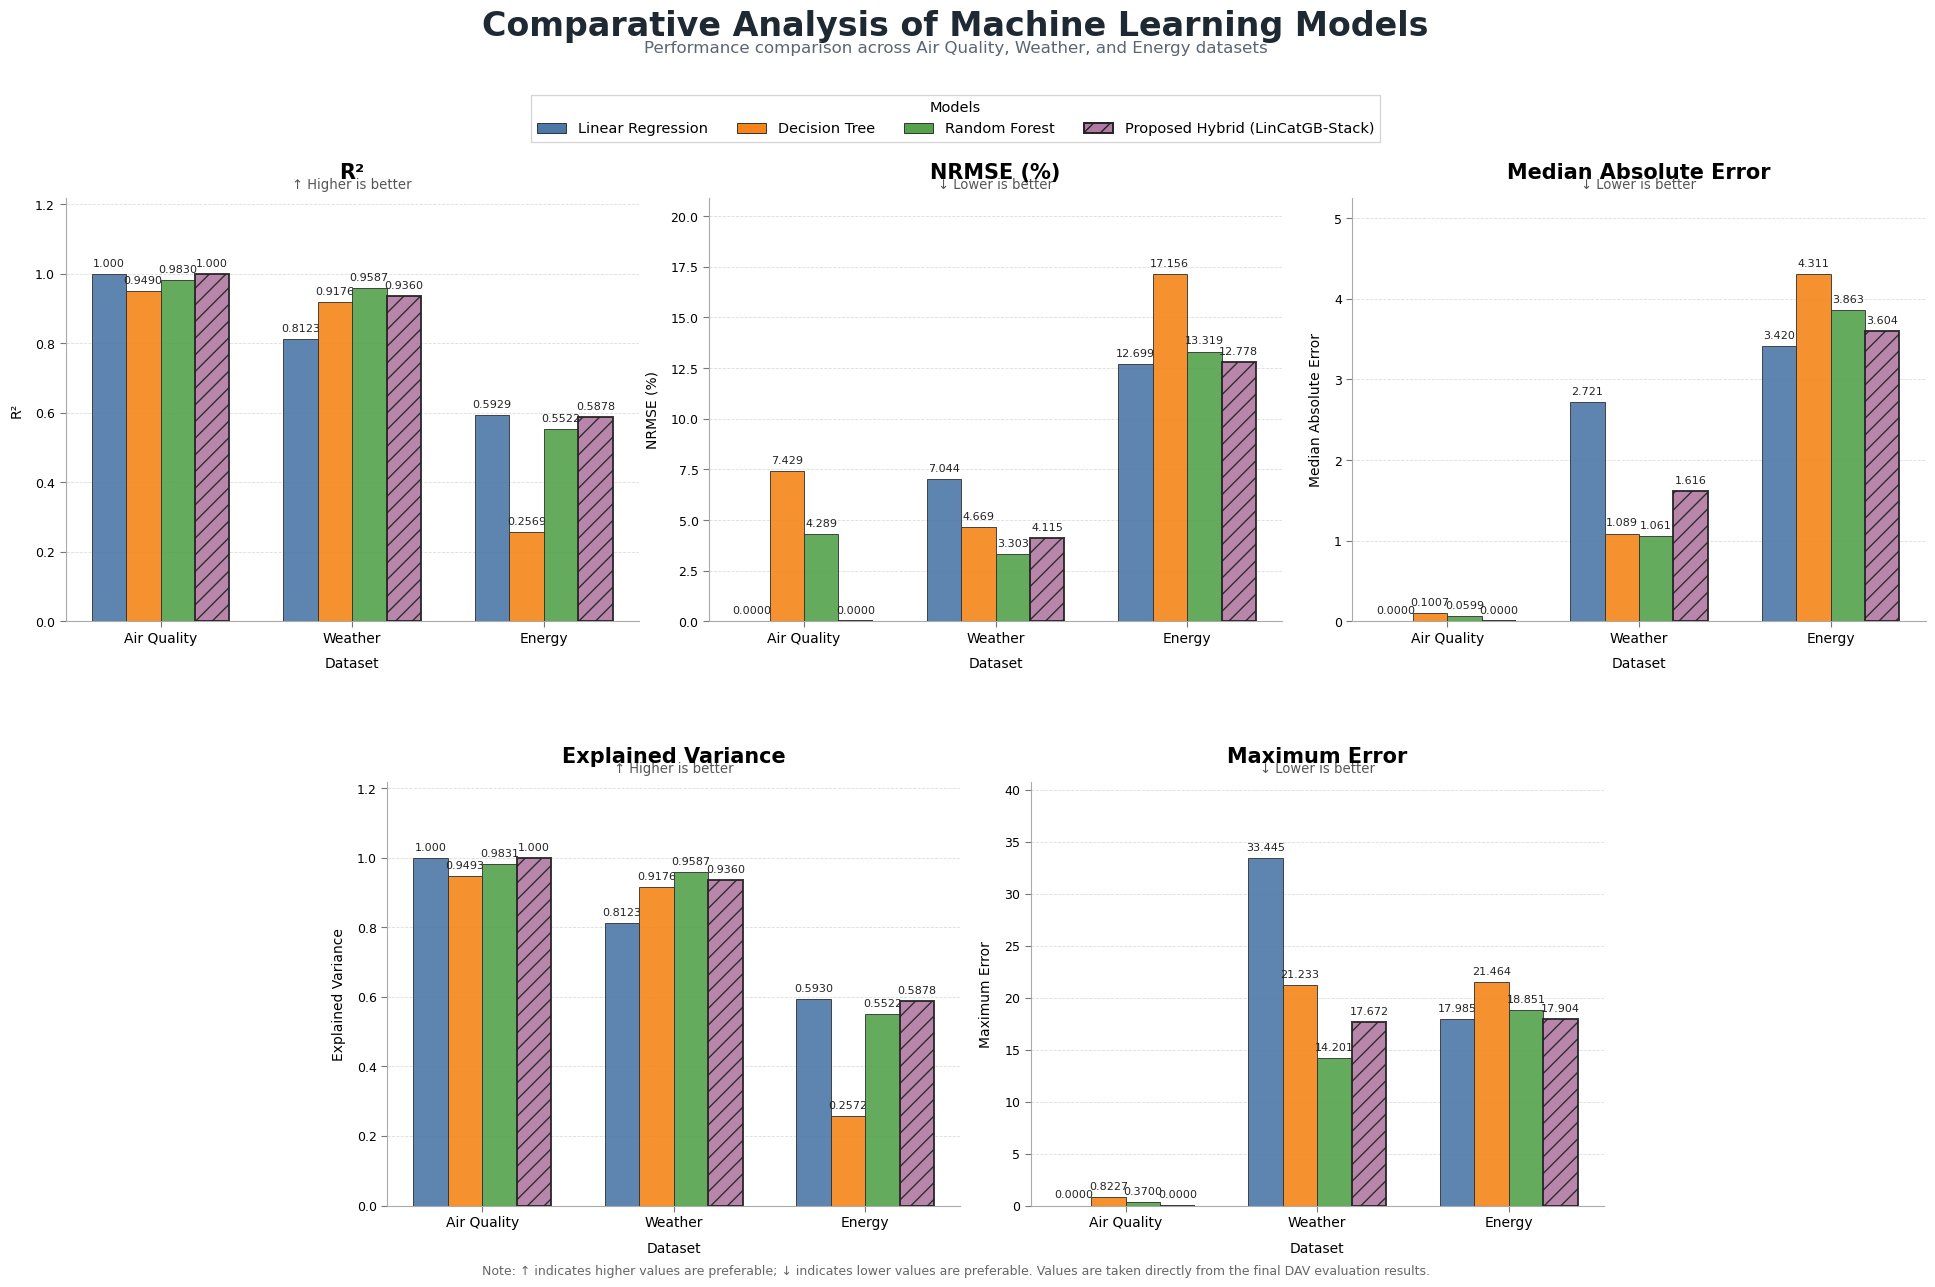


FINAL DAV COMPARATIVE ANALYSIS GENERATED SUCCESSFULLY

PNG:
..\..\Hybrid_Model\Results\DAV_Comparative_Model_Performance.png

PDF:
..\..\Hybrid_Model\Results\DAV_Comparative_Model_Performance.pdf

Figure contains:
• 5 performance metrics
• 3 datasets
• 4 models
• Exact values from the final metrics table
• 300 DPI PNG
• Vector PDF


In [1]:
# ============================================================
# DAV PROJECT
# Comparative Analysis of Machine Learning Models
# Final Research-Style Visualization
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.patches import Patch


# ============================================================
# 1. FIND THE FINAL METRICS TABLE
# ============================================================

filename = "Final_DAV_Metrics_Table.csv"

possible_paths = [
    Path("../../Hybrid_Model/Results") / filename,
    Path("../../Hybrid_Model/Results") / filename,
    Path("../../Hybrid_Model/Results") / filename,
]

metrics_path = None

for path in possible_paths:
    if path.exists():
        metrics_path = path
        break

# If not found in the usual locations, search from current folder
if metrics_path is None:
    matches = list(Path.cwd().rglob(filename))

    if len(matches) > 0:
        metrics_path = matches[0]

if metrics_path is None:
    raise FileNotFoundError(
        "Final_DAV_Metrics_Table.csv was not found."
    )

print("Using metrics file:")
print(metrics_path)


# ============================================================
# 2. LOAD THE EXACT PROJECT RESULTS
# ============================================================

df = pd.read_csv(metrics_path)

print("\nLoaded data:")
print(df.shape)
print(df.columns.tolist())


# ============================================================
# 3. CHECK REQUIRED COLUMNS
# ============================================================

required_columns = [
    "Dataset",
    "Model",
    "R2",
    "NRMSE_percent",
    "Median_AE",
    "Explained_Variance",
    "Max_Error"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )


# ============================================================
# 4. DEFINE THE EXACT PROJECT ORDER
# ============================================================

dataset_order = [
    "Air Quality",
    "Weather",
    "Energy"
]

model_order = [
    "Linear Regression",
    "Decision Tree",
    "Random Forest",
    "Proposed Hybrid"
]

# Convert to categorical ordering
df["Dataset"] = pd.Categorical(
    df["Dataset"],
    categories=dataset_order,
    ordered=True
)

df["Model"] = pd.Categorical(
    df["Model"],
    categories=model_order,
    ordered=True
)

# Sort
df = df.sort_values(
    ["Dataset", "Model"]
).reset_index(drop=True)


# ============================================================
# 5. VERIFY THAT WE HAVE EXACTLY 12 COMPARISONS
# ============================================================

expected_rows = len(dataset_order) * len(model_order)

if len(df) != expected_rows:
    raise ValueError(
        f"Expected {expected_rows} rows "
        f"(3 datasets × 4 models), but found {len(df)}."
    )

print("\nVerified:")
print(f"{len(dataset_order)} datasets × {len(model_order)} models")
print(f"Total rows = {len(df)}")


# ============================================================
# 6. METRICS USED IN THE FINAL FIGURE
# ============================================================

metrics = [
    {
        "column": "R2",
        "title": "R²",
        "direction": "↑ Higher is better",
        "direction_type": "higher"
    },
    {
        "column": "NRMSE_percent",
        "title": "NRMSE (%)",
        "direction": "↓ Lower is better",
        "direction_type": "lower"
    },
    {
        "column": "Median_AE",
        "title": "Median Absolute Error",
        "direction": "↓ Lower is better",
        "direction_type": "lower"
    },
    {
        "column": "Explained_Variance",
        "title": "Explained Variance",
        "direction": "↑ Higher is better",
        "direction_type": "higher"
    },
    {
        "column": "Max_Error",
        "title": "Maximum Error",
        "direction": "↓ Lower is better",
        "direction_type": "lower"
    }
]


# ============================================================
# 7. PROFESSIONAL MODEL COLORS
# ============================================================

# Same model = same color throughout the entire figure
model_colors = {
    "Linear Regression": "#4C78A8",
    "Decision Tree": "#F58518",
    "Random Forest": "#54A24B",
    "Proposed Hybrid": "#B279A2"
}


# ============================================================
# 8. CREATE FINAL FIGURE
# ============================================================

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 14,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9
})

fig = plt.figure(
    figsize=(20, 13),
    facecolor="white"
)

# 2 rows × 6 columns
#
# Top:
# [Panel 1][Panel 2][Panel 3]
#
# Bottom:
#     [Panel 4][Panel 5]
#
# This keeps the fifth panel visually centered.
gs = fig.add_gridspec(
    2,
    6,
    hspace=0.38,
    wspace=0.28
)

axes = [
    fig.add_subplot(gs[0, 0:2]),
    fig.add_subplot(gs[0, 2:4]),
    fig.add_subplot(gs[0, 4:6]),
    fig.add_subplot(gs[1, 1:3]),
    fig.add_subplot(gs[1, 3:5])
]


# ============================================================
# 9. COMMON BAR SETTINGS
# ============================================================

n_models = len(model_order)

bar_width = 0.18

# Positions for four models inside each dataset group
offsets = np.array([
    -1.5,
    -0.5,
     0.5,
     1.5
]) * bar_width

dataset_positions = np.arange(
    len(dataset_order)
)


# ============================================================
# 10. FUNCTION FOR VALUE LABEL PRECISION
# ============================================================

def format_value(value):

    if pd.isna(value):
        return "N/A"

    value = float(value)

    # Very small values
    if abs(value) < 0.001:
        return f"{value:.4f}"

    # Values below 1
    elif abs(value) < 1:
        return f"{value:.4f}"

    # Normal values
    elif abs(value) < 100:
        return f"{value:.3f}"

    # Large values
    else:
        return f"{value:.2f}"


# ============================================================
# 11. DRAW EACH METRIC PANEL
# ============================================================

for ax, metric_info in zip(axes, metrics):

    column = metric_info["column"]
    title = metric_info["title"]
    direction = metric_info["direction"]

    # --------------------------------------------
    # Draw four model bars for each dataset
    # --------------------------------------------

    for model_index, model in enumerate(model_order):

        model_data = []

        for dataset in dataset_order:

            row = df[
                (df["Dataset"] == dataset) &
                (df["Model"] == model)
            ]

            if len(row) != 1:
                raise ValueError(
                    f"Expected exactly one row for "
                    f"{dataset} + {model}"
                )

            model_data.append(
                row.iloc[0][column]
            )

        model_data = np.array(
            model_data,
            dtype=float
        )

        x_positions = (
            dataset_positions
            + offsets[model_index]
        )

        bars = ax.bar(
            x_positions,
            model_data,
            width=bar_width,
            label=model,
            color=model_colors[model],
            edgecolor="#333333",
            linewidth=0.7,
            alpha=0.90,
            zorder=3
        )

        # ----------------------------------------
        # Special visual treatment for Proposed Hybrid
        # ----------------------------------------

        if model == "Proposed Hybrid":

            for bar in bars:

                bar.set_hatch("//")
                bar.set_linewidth(1.4)
                bar.set_edgecolor("#222222")

        # ----------------------------------------
        # Add exact value labels
        # ----------------------------------------

        for bar, value in zip(
            bars,
            model_data
        ):

            if pd.isna(value):
                continue

            height = bar.get_height()

            # Determine offset depending on sign
            if height >= 0:
                vertical_offset = 4
                va = "bottom"
            else:
                vertical_offset = -4
                va = "top"

            ax.annotate(
                format_value(value),
                xy=(
                    bar.get_x() + bar.get_width() / 2,
                    height
                ),
                xytext=(
                    0,
                    vertical_offset
                ),
                textcoords="offset points",
                ha="center",
                va=va,
                fontsize=8,
                fontweight="medium",
                color="#222222",
                clip_on=False
            )


    # ========================================================
    # PANEL FORMATTING
    # ========================================================

    ax.set_title(
        title,
        fontsize=15,
        fontweight="bold",
        pad=14
    )

    # Direction indicator
    ax.text(
        0.5,
        1.015,
        direction,
        transform=ax.transAxes,
        ha="center",
        va="bottom",
        fontsize=9.5,
        fontweight="medium",
        color="#555555"
    )

    # Dataset labels
    ax.set_xticks(
        dataset_positions
    )

    ax.set_xticklabels(
        dataset_order,
        fontsize=10,
        fontweight="medium"
    )

    ax.set_xlabel(
        "Dataset",
        fontsize=10,
        labelpad=8
    )

    ax.set_ylabel(
        title,
        fontsize=10,
        labelpad=8
    )

    # --------------------------------------------
    # Gridlines
    # --------------------------------------------

    ax.yaxis.grid(
        True,
        linestyle="--",
        linewidth=0.6,
        alpha=0.25,
        color="#777777",
        zorder=0
    )

    ax.xaxis.grid(
        False
    )

    # --------------------------------------------
    # Clean borders
    # --------------------------------------------

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.spines["left"].set_color("#AAAAAA")
    ax.spines["bottom"].set_color("#AAAAAA")

    # --------------------------------------------
    # Tick styling
    # --------------------------------------------

    ax.tick_params(
        axis="both",
        which="major",
        length=4,
        color="#777777"
    )

    # --------------------------------------------
    # Give value labels enough room
    # --------------------------------------------

    y_min, y_max = ax.get_ylim()

    if y_min >= 0:

        ax.set_ylim(
            0,
            y_max * 1.16
        )

    else:

        margin = (
            y_max - y_min
        ) * 0.12

        ax.set_ylim(
            y_min - margin,
            y_max + margin
        )


# ============================================================
# 12. MAIN TITLE
# ============================================================

fig.suptitle(
    "Comparative Analysis of Machine Learning Models",
    fontsize=24,
    fontweight="bold",
    color="#1F2933",
    y=0.985
)


# ============================================================
# 13. SUBTITLE
# ============================================================

fig.text(
    0.5,
    0.955,
    "Performance comparison across Air Quality, Weather, and Energy datasets",
    ha="center",
    va="center",
    fontsize=12,
    color="#5B6573"
)


# ============================================================
# 14. COMMON LEGEND
# ============================================================

legend_handles = []

for model in model_order:

    if model == "Proposed Hybrid":

        display_name = "Proposed Hybrid (LinCatGB-Stack)"

        handle = Patch(
            facecolor=model_colors[model],
            edgecolor="#222222",
            hatch="//",
            linewidth=1.4,
            label=display_name
        )

    else:

        handle = Patch(
            facecolor=model_colors[model],
            edgecolor="#333333",
            linewidth=0.7,
            label=model
        )

    legend_handles.append(handle)


fig.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.925),
    ncol=4,
    frameon=True,
    fancybox=False,
    edgecolor="#CCCCCC",
    facecolor="white",
    fontsize=10.5,
    title="Models",
    title_fontsize=10.5
)


# ============================================================
# 15. FOOTNOTE
# ============================================================

fig.text(
    0.5,
    0.015,
    "Note: ↑ indicates higher values are preferable; ↓ indicates lower values are preferable. "
    "Values are taken directly from the final DAV evaluation results.",
    ha="center",
    va="center",
    fontsize=9,
    color="#666666"
)


# ============================================================
# 16. FINAL LAYOUT
# ============================================================

fig.subplots_adjust(
    top=0.84,
    bottom=0.065,
    left=0.055,
    right=0.985,
    hspace=0.42,
    wspace=0.28
)


# ============================================================
# 17. SAVE OUTPUTS
# ============================================================

output_directory = metrics_path.parent

png_path = (
    output_directory
    / "DAV_Comparative_Model_Performance.png"
)

pdf_path = (
    output_directory
    / "DAV_Comparative_Model_Performance.pdf"
)


# High-resolution PNG
fig.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)


# Vector PDF
fig.savefig(
    pdf_path,
    bbox_inches="tight",
    facecolor="white"
)


# ============================================================
# 18. DISPLAY
# ============================================================

plt.show()


# ============================================================
# 19. FINAL CONFIRMATION
# ============================================================

print("\n" + "=" * 70)
print("FINAL DAV COMPARATIVE ANALYSIS GENERATED SUCCESSFULLY")
print("=" * 70)

print("\nPNG:")
print(png_path)

print("\nPDF:")
print(pdf_path)

print("\nFigure contains:")
print("• 5 performance metrics")
print("• 3 datasets")
print("• 4 models")
print("• Exact values from the final metrics table")
print("• 300 DPI PNG")
print("• Vector PDF")
print("=" * 70)